# Kernele do detekcji linii: pierścień antypodalny i Hessian

Notatnik dydaktyczny: na małych, sztucznych obrazkach (linia, gwiazda, duża plama) pokazuje,
**co liczą** obie metody i **dlaczego** odróżniają linię od gwiazdy. Bez pełnej klatki.

1. **Pierścień antypodalny** – działa na masce binarnej (np. `threshold`): czy przeciwległe punkty
   okręgu wokół piksela są w masce?
2. **Hessian** – działa na obrazie (po odjęciu tła): macierz drugich pochodnych, jej wartości
   i wektory własne mówią, czy piksel leży na grzbiecie (linii), czy na kopule (gwieździe).

Obie dają to samo: **miarę liniowości** piksela i **lokalny kierunek** – czyli dokładnie to,
czego potrzebuje Hough głosujący tylko w ±Δθ.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

N = 41                      # male obrazki 41 x 41, srodek w (20, 20)
c = N // 2
yy, xx = np.mgrid[0:N, 0:N].astype(float)

def line_dist(theta_deg, x0=c, y0=c):
    # odleglosc od prostej przez (x0, y0) pod katem theta (od osi x)
    t = np.deg2rad(theta_deg)
    return np.abs(-(xx - x0) * np.sin(t) + (yy - y0) * np.cos(t))

def show(ax, img, title, cmap="gray_r", **kw):
    ax.imshow(img, origin="lower", cmap=cmap, interpolation="nearest", **kw)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

---
# Część 1: pierścień antypodalny (na masce)

Maska $M(p)\in\{0,1\}$. Okrąg o promieniu $R$, $K$ punktów pod kątami $\varphi_k = 2\pi k/K$,
przesunięcia $d_k = \mathrm{round}(R\cos\varphi_k,\ R\sin\varphi_k)$. Dla piksela $p$:

$$P_k(p) = M(p+d_k)\,M(p-d_k)\qquad k=0\ldots K/2-1 \quad\text{(para przeciwległa)}$$
$$O(p) = \frac1K\sum_{k=0}^{K-1} M(p+d_k)\qquad\text{(zajętość pierścienia)}$$
$$L(p) = M(p)\cdot\max_k P_k(p)\cdot[\,O(p) < O_{max}\,],\qquad \theta(p)=\varphi_{k^*}\ (\mathrm{mod}\ 180^\circ)$$

Uwaga: to **nie jest splot**. Splot (suma $M$ po pierścieniu) daje tylko $O$, a $O$ nie odróżnia
linii od brzegu plamy. Kluczowy jest **iloczyn przeciwległych punktów**.

In [2]:
R, K = 5, 16
phi = 2 * np.pi * np.arange(K) / K
dx = np.rint(R * np.cos(phi)).astype(int)
dy = np.rint(R * np.sin(phi)).astype(int)
print(" k   phi    dx  dy")
for k in range(K):
    print(f"{k:2d} {np.degrees(phi[k]):6.1f}  {dx[k]:3d} {dy[k]:3d}" + ("   <- para z k=%d" % (k - K // 2) if k >= K // 2 else ""))

 k   phi    dx  dy
 0    0.0    5   0
 1   22.5    5   2
 2   45.0    4   4
 3   67.5    2   5
 4   90.0    0   5
 5  112.5   -2   5
 6  135.0   -4   4
 7  157.5   -5   2
 8  180.0   -5   0   <- para z k=0
 9  202.5   -5  -2   <- para z k=1
10  225.0   -4  -4   <- para z k=2
11  247.5   -2  -5   <- para z k=3
12  270.0    0  -5   <- para z k=4
13  292.5    2  -5   <- para z k=5
14  315.0    4  -4   <- para z k=6
15  337.5    5  -2   <- para z k=7


### Cztery obrazki testowe (maski binarne)

* **linia** 0°, szerokość 3 px,
* **gwiazda** – dysk o promieniu 3 px (mniejszy niż $R$),
* **duża plama** – dysk o promieniu 10 px (saturowana gwiazda, większa niż $R$),
* **linia 30°** – do pokazania, po co gęste $K$.

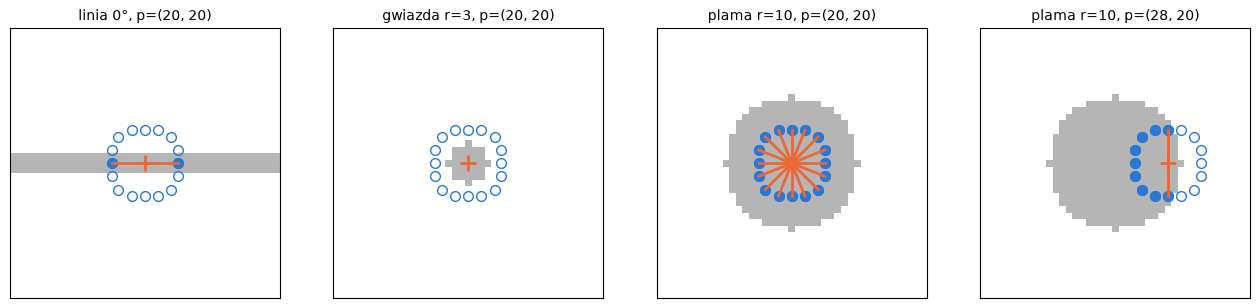

linia 0°               p=(20, 20)  M(p+d_k)=1000000010000000  P_k=10000000  O=0.12  L=1  theta=0.0
gwiazda r=3            p=(20, 20)  M(p+d_k)=0000000000000000  P_k=00000000  O=0.00  L=0  theta=nan
plama r=10             p=(20, 20)  M(p+d_k)=1111111111111111  P_k=11111111  O=1.00  L=0  theta=0.0
plama r=10             p=(28, 20)  M(p+d_k)=0000111111111000  P_k=00001000  O=0.56  L=0  theta=90.0


In [3]:
masks = {
    "linia 0°":      line_dist(0) <= 1.5,
    "gwiazda r=3":   np.hypot(xx - c, yy - c) <= 3,
    "plama r=10":    np.hypot(xx - c, yy - c) <= 10,
    "linia 30°":     line_dist(30) <= 1.5,
}

def ring_at(M, p, dx, dy):
    # wartosci maski w K punktach okregu wokol p = (x, y)
    x, y = p
    return np.array([M[y + j, x + i] if 0 <= y + j < N and 0 <= x + i < N else 0
                     for i, j in zip(dx, dy)], dtype=int)

def ring_report(M, p, dx, dy, O_max=0.35, name=""):
    K = len(dx)
    m = ring_at(M, p, dx, dy)
    P = m[:K // 2] * m[K // 2:]
    O = m.mean()
    L = int(M[p[1], p[0]] and P.any() and O < O_max)
    th = np.degrees(phi_of(K)[np.argmax(P)]) % 180 if P.any() else np.nan
    print(f"{name:22s} p={p}  M(p+d_k)={''.join(map(str, m))}  P_k={''.join(map(str, P))}  "
          f"O={O:.2f}  L={L}  theta={th:.1f}")
    return m, P

def phi_of(K):
    return 2 * np.pi * np.arange(K) / K

def draw_ring(ax, M, p, dx, dy, title):
    K = len(dx)
    m = ring_at(M, p, dx, dy)
    P = m[:K // 2] * m[K // 2:]
    show(ax, M, title, cmap="Greys", vmin=0, vmax=2.5)
    ax.plot(p[0] + dx, p[1] + dy, "o", mfc="none", mec="#2a78d6", ms=7)
    ax.plot((p[0] + dx)[m == 1], (p[1] + dy)[m == 1], "o", color="#2a78d6", ms=7)
    for k in np.nonzero(P)[0]:
        ax.plot([p[0] + dx[k], p[0] - dx[k]], [p[1] + dy[k], p[1] - dy[k]], "-", color="#eb6834", lw=2)
    ax.plot(*p, "+", color="#eb6834", ms=12, mew=2)

cases = [("linia 0°", (c, c)), ("gwiazda r=3", (c, c)), ("plama r=10", (c, c)), ("plama r=10", (c + 8, c))]
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, p) in zip(axs, cases):
    draw_ring(ax, masks[name], p, dx, dy, f"{name}, p={p}")
plt.show()
for name, p in cases:
    ring_report(masks[name], p, dx, dy, name=name)

Kółka: punkty okręgu (pełne = w masce). Pomarańczowe odcinki: pary przeciwległe z $P_k=1$.

| przypadek | co się dzieje | wynik |
|---|---|---|
| linia 0° | okrąg przecina linię w 2 przeciwległych miejscach → jedna para | $L=1$, $\theta=0°$, $O=2/16$ |
| gwiazda r=3 < R | okrąg cały poza gwiazdą | $O=0$, $L=0$ |
| plama r=10, środek | okrąg cały w plamie → wszystkie pary | $O=1$ → odrzucona przez $O_{max}$ |
| plama r=10, brzeg | **pułapka**: para styczna do brzegu też ma oba końce w plamie | $P=1$, ale $O\approx0.5$ → odrzucona |

Dlatego potrzebny jest warunek $O < O_{max}$ (tu $O_{max}=0.35$): linia zajmuje tylko
$\approx 2\cdot\frac{w}{2\pi R/K}$ punktów okręgu (tu 2–4 z 16, $O\le0.25$), a brzeg plamy około połowy.

### Po co gęste $K$: linia pod 30°

Punkt okręgu trafia w linię o szerokości $w$, jeśli leży w odległości $\le w/2$ od jej osi.
Sąsiednie punkty okręgu są oddalone o $2\pi R/K$, więc żeby zawsze któryś trafił:

$$K \gtrsim \frac{2\pi R}{w}\qquad (R=5,\ w=3 \Rightarrow K\approx 11 \Rightarrow 16)$$

linia 30°, K=8         p=(20, 20)  M(p+d_k)=01000100  P_k=0100  O=0.25  L=1  theta=45.0
linia 30°, K=16        p=(20, 20)  M(p+d_k)=0110000001100000  P_k=01100000  O=0.25  L=1  theta=22.5


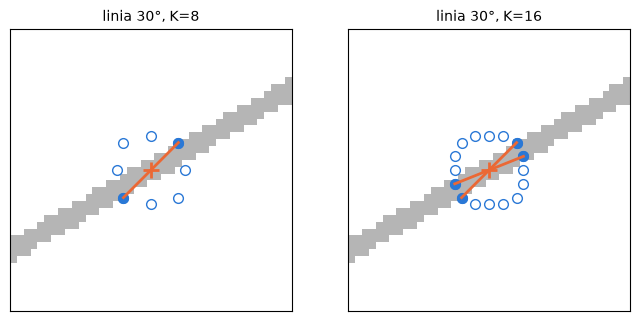

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4))
for ax, KK in zip(axs, (8, 16)):
    f = phi_of(KK)
    ddx, ddy = np.rint(R * np.cos(f)).astype(int), np.rint(R * np.sin(f)).astype(int)
    draw_ring(ax, masks["linia 30°"], (c, c), ddx, ddy, f"linia 30°, K={KK}")
    ring_report(masks["linia 30°"], (c, c), ddx, ddy, name=f"linia 30°, K={KK}")
plt.show()

Przy $K=8$ (krok 45°) para najbliższa 30° (czyli 45°) leży na granicy szerokości linii.
Przy $K=16$ (krok 22.5°) trafia para 22.5°, a kierunek ma rozdzielczość $180°/(K/2)$.

### Mapa dla całej sceny

Teraz to samo dla każdego piksela naraz. Implementacja: $K$ przesuniętych kopii maski
i $K/2$ iloczynów – same operacje na tablicach, bez pętli po pikselach.

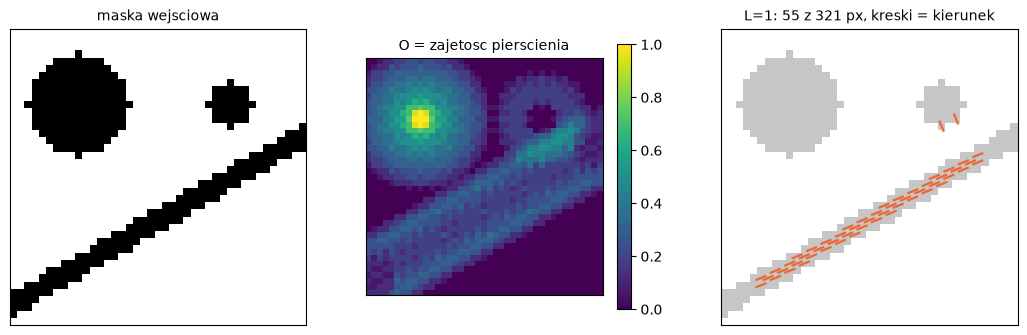

kierunek na linii: mediana 22.5 deg (prawda 30)


In [5]:
def shifted(M, i, j):
    # S[p] = M[p + (i, j)], zero poza obrazem
    S = np.zeros_like(M)
    ny, nx = M.shape
    S[max(0, -j):ny - max(0, j), max(0, -i):nx - max(0, i)] = \
        M[max(0, j):ny - max(0, -j), max(0, i):nx - max(0, -i)]
    return S

def ring_test(M, R, K, O_max=0.35):
    f = phi_of(K)
    ddx, ddy = np.rint(R * np.cos(f)).astype(int), np.rint(R * np.sin(f)).astype(int)
    S = np.array([shifted(M, i, j) for i, j in zip(ddx, ddy)])        # K x ny x nx
    O = S.mean(axis=0)
    P = S[:K // 2] & S[K // 2:]                                        # K/2 x ny x nx
    L = M & P.any(axis=0) & (O < O_max)
    theta = np.where(L, np.degrees(f[np.argmax(P, axis=0)]) % 180, np.nan)
    return L, theta, O

# scena: linia 30 deg + gwiazda + duza plama
scene = (line_dist(30, c, c - 6) <= 1.5) | (np.hypot(xx - 30, yy - 30) <= 3) | (np.hypot(xx - 9, yy - 30) <= 7)
L, theta, O = ring_test(scene, R=5, K=16)

fig, axs = plt.subplots(1, 3, figsize=(13, 4.3))
show(axs[0], scene, "maska wejsciowa", cmap="Greys")
show(axs[1], O, "O = zajetosc pierscienia", cmap="viridis"); plt.colorbar(axs[1].images[0], ax=axs[1], shrink=0.8)
show(axs[2], scene, f"L=1: {L.sum()} z {scene.sum()} px, kreski = kierunek", cmap="Greys", vmin=0, vmax=3)
ys, xs = np.nonzero(L)
t = np.deg2rad(theta[L])
axs[2].quiver(xs, ys, np.cos(t), np.sin(t), color="#eb6834", headwidth=0, headlength=0,
              headaxislength=0, pivot="mid", scale=25)
plt.show()
print("kierunek na linii: mediana", np.nanmedian(theta[L]), "deg (prawda 30)")

Gwiazda i plama znikają, zostaje linia z kierunkiem ≈ 30° (z dokładnością do kroku 22.5°).
Końce linii (bliżej niż $R$ od końca) i miejsce zetknięcia z plamą też odpadają – dla Hougha to bez znaczenia.

### Statystyka: szum i poszarpana linia

* **Szum:** piksel jest fałszywie w masce z prawdopodobieństwem $p$ (przy 3σ: $p\approx0.0013$).
  Para wymaga obu końców: $p^2$, na $K/2$ par $\approx \tfrac K2 p^2 \sim 10^{-5}$ – szum znika.
* **Słaba, poszarpana linia** z wypełnieniem $f$: para przeżywa z prawdopodobieństwem $\approx f^2$.
  To jest główny koszt metody.

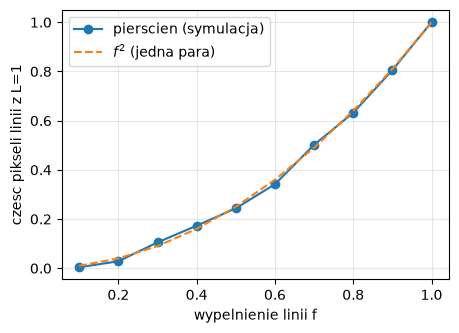

In [6]:
rng = np.random.default_rng(1)
base = line_dist(0) <= 1.5
fs = np.linspace(0.1, 1, 10)
kept = []
for f in fs:
    vals = []
    for _ in range(50):
        M = base & (rng.random(base.shape) < f)
        Lf, _, _ = ring_test(M, R=5, K=16)
        core = M & (np.abs(xx - c) < c - 6)            # bez koncow linii
        vals.append(Lf[core].sum() / max(core.sum(), 1))
    kept.append(np.mean(vals))
plt.figure(figsize=(5, 3.5))
plt.plot(fs, kept, "o-", label="pierscien (symulacja)")
plt.plot(fs, fs ** 2, "--", label="$f^2$ (jedna para)")
plt.xlabel("wypelnienie linii f"); plt.ylabel("czesc pikseli linii z L=1"); plt.legend(); plt.grid(alpha=.3)
plt.show()

Symulacja jest nieco powyżej $f^2$, bo linia o szerokości 3 px daje zwykle kilka par
(sąsiednie punkty okręgu też w nią trafiają) – każda to osobna szansa.

---
# Część 2: Hessian (na obrazie)

Obraz $I$ wygładzony Gaussem o skali $s$. Hessian to macierz drugich pochodnych:

$$H = \begin{pmatrix} I_{xx} & I_{xy}\\ I_{xy} & I_{yy}\end{pmatrix},\qquad
\lambda_{1,2} = \frac{I_{xx}+I_{yy}}{2} \mp \sqrt{\left(\frac{I_{xx}-I_{yy}}{2}\right)^2 + I_{xy}^2},\quad \lambda_1\le\lambda_2$$

Wartości własne to **krzywizny** obrazu w dwóch prostopadłych kierunkach (wektory własne).
Dla jasnych obiektów na tle:

| obiekt | $\lambda_1$ (w poprzek) | $\lambda_2$ (wzdłuż) | kształt |
|---|---|---|---|
| linia (grzbiet) | silnie ujemna | ≈ 0 | rynna odwrócona |
| gwiazda (środek) | ujemna | tak samo ujemna | kopuła |
| tło | ≈ 0 | ≈ 0 | płasko |

Miary: **siła** $S = -s^2\lambda_1$ (normalizacja $s^2$, żeby porównywać skale),
**anizotropia** $A = 1 - |\lambda_2|/|\lambda_1|$ (1 = linia, 0 = kopuła),
**kierunek linii** = wektor własny $\lambda_2$: $\ \theta = \tfrac12\,\mathrm{atan2}(2I_{xy},\ I_{xx}-I_{yy})$.

### 1D: przekrój w poprzek linii

Linia o profilu $I(y)=A\,e^{-y^2/2w^2}$ po wygładzeniu Gaussem $s$ ma szerokość
$\sigma^2=w^2+s^2$ i amplitudę $A\,w/\sigma$. Druga pochodna w środku:

$$I''(0) = -\frac{A\,w}{\sigma^3},\qquad s^2 I''(0) = -\frac{A\,w\,s^2}{(w^2+s^2)^{3/2}}$$

Maksimum $|s^2 I''|$ wypada dla $s=\sqrt2\,w$ – to **optymalna skala** Hessianu dla linii o szerokości $w$.

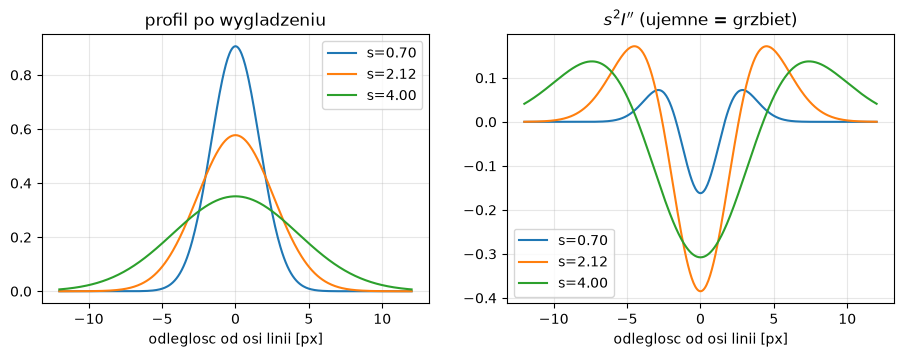

max |s^2 I''| dla s = 2.12  (sqrt(2) w = 2.12)


In [7]:
y = np.linspace(-12, 12, 401)
A, w = 1.0, 1.5
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
for s in (0.7, np.sqrt(2) * w, 4.0):
    sig = np.hypot(w, s)
    I = A * w / sig * np.exp(-y ** 2 / (2 * sig ** 2))
    I2 = I * (y ** 2 / sig ** 4 - 1 / sig ** 2)
    axs[0].plot(y, I, label=f"s={s:.2f}")
    axs[1].plot(y, s ** 2 * I2, label=f"s={s:.2f}")
axs[0].set_title("profil po wygladzeniu"); axs[1].set_title("$s^2 I''$ (ujemne = grzbiet)")
for ax in axs: ax.legend(); ax.grid(alpha=.3); ax.set_xlabel("odleglosc od osi linii [px]")
plt.show()

ss = np.linspace(0.2, 6, 200)
resp = A * w * ss ** 2 / (w ** 2 + ss ** 2) ** 1.5
print(f"max |s^2 I''| dla s = {ss[np.argmax(resp)]:.2f}  (sqrt(2) w = {np.sqrt(2) * w:.2f})")

### 2D: macierz H w kilku punktach

Obrazki natężeniowe (już nie maski): linia 30° o szerokości $w=1.5$, gwiazda gaussowska
$\sigma_*=1.7$ (FWHM 4). Liczymy $H$ w środku linii, w środku gwiazdy, na zboczu gwiazdy
($r=\sigma$, gdzie $\sigma=\sqrt{\sigma_*^2+s^2}\approx2.7$ to szerokość gwiazdy **po wygładzeniu**) i na tle.

In [8]:
def hessian(img, s):
    Ixx = gaussian_filter(img, s, order=(0, 2))     # order = (y, x)
    Iyy = gaussian_filter(img, s, order=(2, 0))
    Ixy = gaussian_filter(img, s, order=(1, 1))
    half_tr = (Ixx + Iyy) / 2
    root = np.sqrt(((Ixx - Iyy) / 2) ** 2 + Ixy ** 2)
    l1, l2 = half_tr - root, half_tr + root
    theta = 0.5 * np.arctan2(2 * Ixy, Ixx - Iyy)      # kierunek wektora wlasnego l2 (wzdluz linii)
    return Ixx, Iyy, Ixy, l1, l2, theta

w, sig_star, s = 1.5, 1.7, np.sqrt(2) * 1.5
line_img = np.exp(-line_dist(30) ** 2 / (2 * w ** 2))
star_img = np.exp(-((xx - c) ** 2 + (yy - c) ** 2) / (2 * sig_star ** 2))

for name, img, p in [("linia 30°, srodek", line_img, (c, c)),
                     ("gwiazda, srodek", star_img, (c, c)),
                     ("gwiazda, zbocze r≈σ", star_img, (c + 3, c)),
                     ("tlo", star_img, (c + 15, c))]:
    Ixx, Iyy, Ixy, l1, l2, th = (a[p[1], p[0]] for a in hessian(img, s))
    A_ = 1 - abs(l2) / abs(l1) if abs(l1) > 1e-6 else np.nan     # na tle l1 ~ 0: A nieokreslone
    print(f"{name:22s} H=[[{Ixx:+.4f} {Ixy:+.4f}] [{Ixy:+.4f} {Iyy:+.4f}]]  "
          f"l1={l1:+.4f} l2={l2:+.4f}  S={-s**2*l1:+.3f}  A={A_:.2f}  theta={np.degrees(th):6.1f}")

linia 30°, srodek      H=[[-0.0214 +0.0370] [+0.0370 -0.0642]]  l1=-0.0855 l2=-0.0000  S=+0.385  A=1.00  theta=  30.0
gwiazda, srodek        H=[[-0.0529 +0.0000] [+0.0000 -0.0529]]  l1=-0.0529 l2=-0.0529  S=+0.238  A=0.00  theta=   0.0
gwiazda, zbocze r≈σ    H=[[+0.0063 +0.0000] [+0.0000 -0.0288]]  l1=-0.0288 l2=+0.0063  S=+0.130  A=0.78  theta=   0.0
tlo                    H=[[+0.0000 +0.0000] [+0.0000 -0.0000]]  l1=-0.0000 l2=+0.0000  S=+0.000  A=nan  theta=   0.0


* **linia:** $\lambda_2\approx0$, $\lambda_1<0$ → $A\approx1$, kierunek 30°.
* **środek gwiazdy:** $\lambda_1=\lambda_2<0$ → $A=0$, kopuła, odrzucona.
* **zbocze gwiazdy** – **pułapka Hessianu**. Na odległości $r$ od środka gwiazdy krzywizny to
  $$\partial_r^2 I = I\left(\frac{r^2}{\sigma^4}-\frac1{\sigma^2}\right),\qquad \frac1r\partial_r I = -\frac{I}{\sigma^2}\ \ (\text{styczna})$$
  Dla $r=\sigma$ krzywizna radialna = 0, a styczna < 0. Silna krzywizna jest więc **w poprzek
  promienia**, czyli piksel wygląda jak **grzbiet biegnący radialnie** (jak szprycha, $A\approx1$,
  kierunek = kierunek do środka gwiazdy; tu na osi x, więc $\theta=0°$). Wokół każdej gwiazdy
  powstaje pierścień takich „szprych”, słabszy niż prawdziwa linia o tej samej jasności, ale przy
  jasnych gwiazdach przechodzi próg.
* **tło:** wszystko ≈ 0, $A$ nieokreślone (0/0) – stąd próg na $S$ przed patrzeniem na $A$.

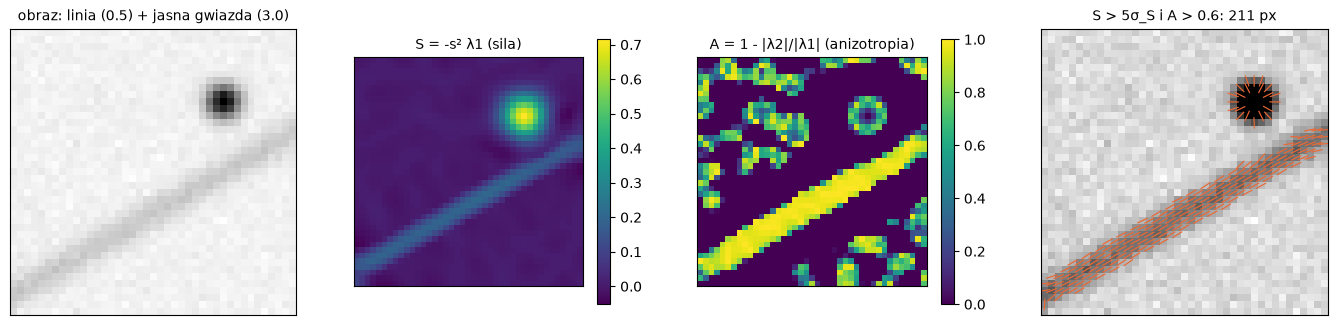

na linii: mediana kierunku 29.9 deg (prawda 30); pikseli poza linia: 71 (pierscien wokol gwiazdy)


In [9]:
rng = np.random.default_rng(3)
scene_img = (0.5 * np.exp(-line_dist(30, c, c - 6) ** 2 / (2 * w ** 2))
             + 3.0 * np.exp(-((xx - 30) ** 2 + (yy - 30) ** 2) / (2 * sig_star ** 2))
             + rng.normal(0, 0.05, xx.shape))
Ixx, Iyy, Ixy, l1, l2, th = hessian(scene_img, s)
S = -s ** 2 * l1
A_ = np.where(l1 < 0, 1 - np.abs(l2) / np.abs(l1), 0)
noise_S = np.median(np.abs(S - np.median(S))) * 1.4826
sel = (S > 5 * noise_S) & (A_ > 0.6)

fig, axs = plt.subplots(1, 4, figsize=(17, 4.3))
show(axs[0], scene_img, "obraz: linia (0.5) + jasna gwiazda (3.0)")
show(axs[1], S, "S = -s² λ1 (sila)", cmap="viridis"); plt.colorbar(axs[1].images[0], ax=axs[1], shrink=0.8)
show(axs[2], A_, "A = 1 - |λ2|/|λ1| (anizotropia)", cmap="viridis", vmin=0, vmax=1)
plt.colorbar(axs[2].images[0], ax=axs[2], shrink=0.8)
show(axs[3], scene_img, f"S > 5σ_S i A > 0.6: {sel.sum()} px", vmax=1)
ys, xs = np.nonzero(sel)
axs[3].quiver(xs, ys, np.cos(th[sel]), np.sin(th[sel]), color="#eb6834", headwidth=0, headlength=0,
              headaxislength=0, pivot="mid", scale=25)
plt.show()
on_line = sel & (line_dist(30, c, c - 6) <= 1.5)
print("na linii: mediana kierunku", round(np.degrees(np.median(th[on_line])), 1), "deg (prawda 30);",
      "pikseli poza linia:", (sel & ~(line_dist(30, c, c - 6) <= 1.5)).sum(), "(pierscien wokol gwiazdy)")

Linia jest wybrana z dokładnym (ciągłym) kierunkiem. Środek gwiazdy odpada ($A\approx0$),
ale wokół jasnej gwiazdy widać **pierścień radialnych „szprych”** – to ten efekt zbocza z tabeli wyżej.
W Houghu każda szprycha głosuje na prostą przechodzącą przez środek gwiazdy, ale pod różnymi
kątami – głosy się rozpraszają, nie budują jednej prostej. Przy kilku sąsiednich szprychach
mogą jednak dać krótki fałszywy odcinek przez gwiazdę (podobny do tych, które widzieliśmy
na jasnych gwiazdach w wk06c). Maska gwiazd usuwa je od razu.

### Hessian a słaba linia: całkowanie

Hessian działa na obrazie, nie na masce: wygładzenie skalą $s$ uśrednia szum wzdłuż i w poprzek
linii, więc widzi linie **poniżej progu pojedynczego piksela**. Poniżej: linia o amplitudzie
1σ szumu – w masce `threshold` (3σ) trafia tylko kilka procent jej pikseli (pierścień dostaje
prawie pustą maskę), a w $S$ każdy piksel linii jest podniesiony o kilka σ szumu $S$. Hough
dodatkowo sumuje to wzdłuż całej linii.

maska 3σ: na linii 0.021, poza linia 0.001  (ring dostaje prawie pusta maske)
S Hessianu: srednia na linii 0.370, poza linia 0.084 +- 0.120  -> 2.4 sigma na piksel


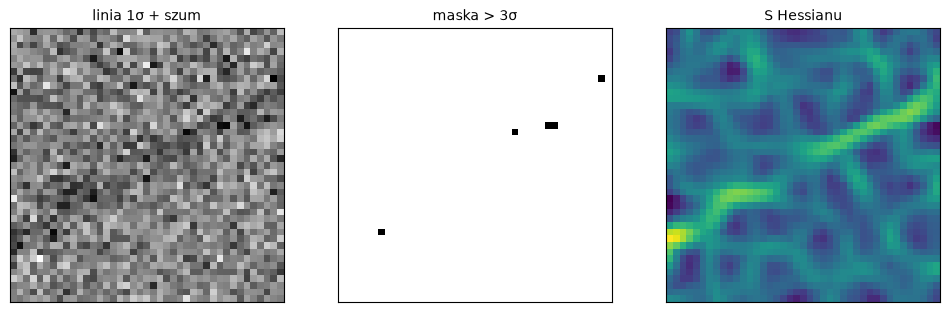

In [10]:
rng = np.random.default_rng(7)
faint = 1.0 * np.exp(-line_dist(30) ** 2 / (2 * w ** 2)) + rng.normal(0, 1.0, xx.shape)
thr = faint > 3.0
on = line_dist(30) <= 1.5
_, _, _, l1f, _, _ = hessian(faint, s)
Sf = -s ** 2 * l1f
print(f"maska 3σ: na linii {thr[on].mean():.3f}, poza linia {thr[~on].mean():.3f}  (ring dostaje prawie pusta maske)")
print(f"S Hessianu: srednia na linii {Sf[on].mean():.3f}, poza linia {Sf[~on].mean():.3f} +- {Sf[~on].std():.3f}"
      f"  -> {(Sf[on].mean() - Sf[~on].mean()) / Sf[~on].std():.1f} sigma na piksel")
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
show(axs[0], faint, "linia 1σ + szum"); show(axs[1], thr, "maska > 3σ", cmap="Greys")
show(axs[2], Sf, "S Hessianu", cmap="viridis")
plt.show()

---
# Podsumowanie

| | pierścień antypodalny | Hessian |
|---|---|---|
| wejście | maska binarna (`threshold`) | obraz − tło |
| co liczy | czy przeciwległe punkty okręgu $R$ są w masce | krzywizny obrazu w skali $s$ |
| odrzuca gwiazdy | gdy gwiazda < $R$ (pusty okrąg) lub duża ($O$ za duże) | środek ($A\approx0$), ale **zbocze** daje fałszywe radialne „szprychy” |
| kierunek | dyskretny, krok $360°/K$ | ciągły |
| słabe linie | tylko to, co jest w masce; poszarpana linia traci ~$1-f^2$ | całkuje sygnał, widzi linie poniżej progu piksela |
| parametry | $R$ (> gwiazdy, < pół linii), $K\gtrsim 2\pi R/w$, $O_{max}$ | $s\approx\sqrt2\,w$, progi na $S$ i $A$ |
| koszt | $K$ przesunięć + $K/2$ iloczynów binarnych | 3 filtry Gaussa z pochodnymi |

Obie metody dają wagę i kierunek do Hougha głosującego tylko w ±Δθ.